# Underwater Acoustic Target Recognition: Feature Fusion (MGCL-Delta) + NCA + ResNet18
**Paper:** Yang, Yao, Wang, *IEEE Sensors Journal* 24(22), 2024. **Runs locally in Jupyter** (no Colab-specific code).

| # | Section | Content |
|---|---|---|
| 1 | DeepShip dataset | Underwater audio recordings of four ship types |
| 2 | Audio preprocessing | Pre-emphasis, framing and windowing |
| 3 | Feature extraction and fusion | MFCC + GFCC + CQT + LOFAR → MGCL; add delta features → MGCL-Delta |
| 4 | Feature selection | Neighborhood Component Analysis (NCA); paper reports reduction to 96 features |
| 5 | Classification | Represent features as 2-D images and classify using ResNet18 |
| 6 | Evaluation | Measure accuracy and compare results with the paper |

**Install:** `pip install jupyter numpy scipy pandas matplotlib scikit-learn soundfile torch torchvision`  


---
# 1. DeepShip dataset
**Goal:** read four classes of ship recordings, check every file, and build an inventory (one row per recording).
**Data source:** the dataset's authors distribute it at `github.com/irfankamboh/DeepShip` `[LITERATURE]` ≈ 613 recordings, 265 ships

In [1]:
#  CONFIG (all paper parameters in one place)
from pathlib import Path
import math, random, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import soundfile as sf
from scipy.signal import get_window, fftconvolve, savgol_filter

SEED = 42
random.seed(SEED); np.random.seed(SEED)
DATA_ROOT = Path("/content/DeepShip")       # where you put the dataset
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
CLASS_NAMES = ("Tug", "Cargo", "Tanker", "Passengership")   # [PAPER] A,B,C,D
CLASS_TO_ID = {n: i for i, n in enumerate(CLASS_NAMES)}
EXPECTED_FS = 32000                         # [LITERATURE]

# --- preprocessing (Section 2)
PREEMPH   = 0.97        # [CHOICE] paper names pre-emphasis but gives no coefficient
FRAME_LEN = 256         # [PAPER] samples
HOP       = 128         # [PAPER] samples
WINDOW    = "hamming"   # [CHOICE] paper names no window type
# --- features (Section 3)
N_MEL, N_MFCC       = 20, 12     # [PAPER] 20 filters -> 12 coefficients
N_GAM, GAM_ORDER    = 64, 4      # [PAPER] 64 gammatone filters, order 4
N_GFCC              = 31         # [PAPER dims = Table II]; [CHOICE] we keep DCT coeffs 1..31
CQT_BINS, CQT_BPO, CQT_FMIN = 41, 12, 20.0   # [CHOICE] chosen so dims = 41 (Table II); paper gives only "12 octaves"
LOFAR_STEP_HZ, LOFAR_BINS = 10, 50           # [PAPER] 10 Hz step up to 500 Hz; [CHOICE] 10..500 Hz = 50 bins (Table II says 50, text says 51)
DELTA_N   = 2           # [PAPER]
# --- dataset size (Section 3b)
CLIP_SECONDS      = 2.5   # [PAPER] example clips are 2.5 s; [CHOICE] we use them as the unit we cut images from
IMAGES_PER_CLASS  = 2360  # [PAPER]
FRAMES_PER_IMAGE  = 5     # [PAPER]
TEST_FRAC, VAL_FRAC = 0.25, 0.10   # [PAPER] 3/4 : 1/4 ; [CHOICE] validation = 10% of train
SPLIT_MODE = "random"     # "random" = paper-style; "recording" = leakage-free extra [CHOICE]
# --- NCA (Section 4)
NCA_THRESHOLD = 0.3       # [PAPER]
NCA_SIGMA, NCA_LAMBDA = 1.0, None   # [CHOICE] paper gives neither (None -> 1/n)
NCA_STEPS, NCA_LR, NCA_MAX_FRAMES = 150, 0.05, 2000   # [CHOICE]
TOP_K_FALLBACK = None     # e.g. 96: keep top-96 weights instead of thresholding (a labelled DEVIATION)
# --- training (Section 6)
BATCH, LR = 5, 0.001      # [PAPER]
MOMENTUM, EPOCHS = 0.9, 15   # [CHOICE] paper says "SGDM" but gives neither
REMOVE_GLOBAL_POOL = False   # [CHOICE] we remove the max-pool after conv1; set True to also drop global avg-pool
print("config loaded")

config loaded


In [2]:
!pip -q install soundfile
!git clone -q --depth 1 https://github.com/irfankamboh/DeepShip /content/DeepShip_repo

def find_class_root(base, names):
    """Find the folder that directly contains the four class folders (case-insensitive)."""
    want = {n.lower() for n in names}
    for d in [base] + sorted(p for p in base.rglob("*") if p.is_dir()):
        have = {c.name.lower() for c in d.iterdir() if c.is_dir()}
        if want <= have:
            return d
    return None

repo = Path("/content/DeepShip_repo")
root = find_class_root(repo, CLASS_NAMES)
if root is None:
    print("Class folders not found. Folders present (with wav counts):")
    for d in sorted(p for p in repo.rglob("*") if p.is_dir() and ".git" not in p.parts):
        print(d.relative_to(repo), "->", len(list(d.glob("*.wav"))))
    print("-> edit CLASS_NAMES in the CONFIG cell to match these names, re-run it, then re-run this cell.")
else:
    DATA_ROOT = root
    print("DATA_ROOT =", DATA_ROOT)
    for c in CLASS_NAMES:
        d = [p for p in root.iterdir() if p.is_dir() and p.name.lower() == c.lower()][0]
        print(f"{c:15s} -> {len(list(d.rglob('*.wav')))} wav files")

DATA_ROOT = /content/DeepShip_repo
Tug             -> 3 wav files
Cargo           -> 12 wav files
Tanker          -> 28 wav files
Passengership   -> 20 wav files


files: 63 | unreadable: 0
label
Tanker           28
Passengership    20
Cargo            12
Tug               3
sampling rates: [np.int64(32000)] | channels: [np.int64(1)]
label
Cargo            0.65
Passengership    0.32
Tanker           0.46
Tug              0.16


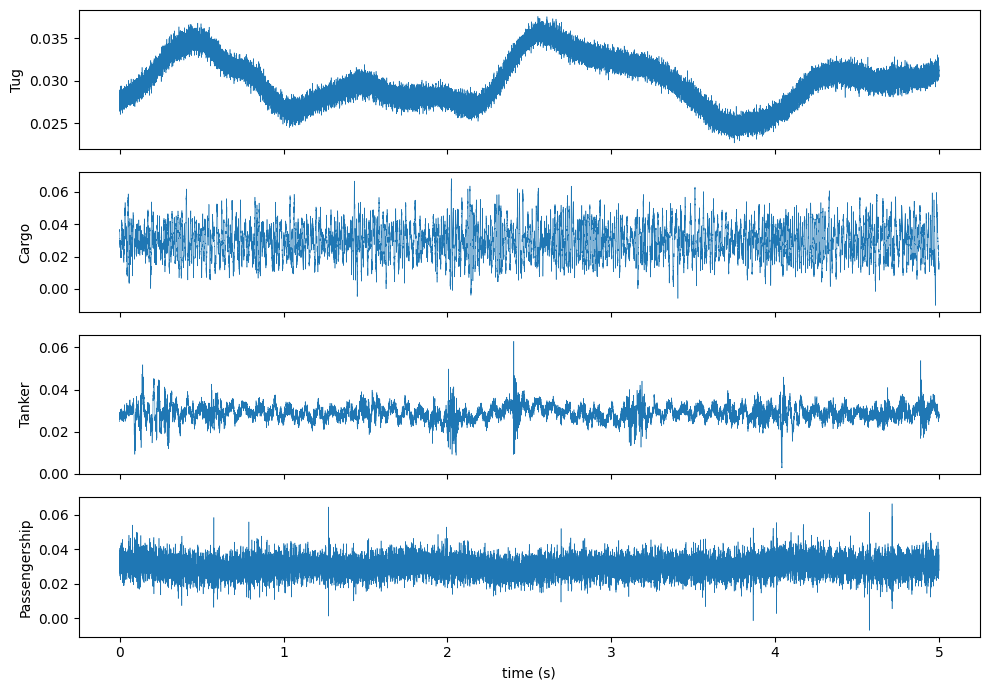

FS = 32000 Hz


In [3]:
# ===================== INVENTORY =====================
def inspect_recording(path, label, deep=False):
    row = {"path": str(path), "recording_id": f"{label}/{path.stem}", "label": label,
           "label_id": CLASS_TO_ID[label], "error": ""}
    try:
        info = sf.info(str(path))                                  # header only
        row.update(fs=info.samplerate, channels=info.channels, n_samples=info.frames,
                   duration_s=info.frames / info.samplerate)       # T = N / fs
        if deep:
            x, _ = sf.read(str(path), dtype="float32", always_2d=True)
            assert x.shape == (info.frames, info.channels)
            row.update(peak=float(np.abs(x).max()), has_nan=bool(np.isnan(x).any()),
                       frac_zero=float((x == 0).mean()))
    except Exception as e:
        row["error"] = f"{type(e).__name__}: {e}"
    return row

def build_inventory(root, deep=False):
    dirs = {d.name.lower(): d for d in root.iterdir() if d.is_dir()}
    rows = []
    for label in CLASS_NAMES:
        assert label.lower() in dirs, f"Class folder '{label}' missing. Found {sorted(dirs)}. Edit CLASS_NAMES."
        files = sorted(p for p in dirs[label.lower()].rglob("*") if p.suffix.lower() in {".wav", ".flac"})
        rows += [inspect_recording(p, label, deep) for p in files]
    return pd.DataFrame(rows)

inv, FS = None, EXPECTED_FS
if DATA_ROOT.exists():
    inv = build_inventory(DATA_ROOT, deep=False)           # deep=True once, later, to catch corruption
    ok = inv[inv.error == ""]
    print("files:", len(inv), "| unreadable:", int((inv.error != "").sum()))
    print(inv.label.value_counts().to_string())
    print("sampling rates:", sorted(ok.fs.unique()), "| channels:", sorted(ok.channels.unique()))
    print((ok.groupby("label").duration_s.sum() / 3600).round(2).rename("hours").to_string())
    assert ok.fs.nunique() == 1, "mixed sampling rates: resample explicitly before continuing"
    FS = int(ok.fs.iloc[0]); inv.to_csv(OUT / "inventory.csv", index=False)
    fig, ax = plt.subplots(4, 1, figsize=(10, 7), sharex=True)         # one 5-second look per class
    for i, lab in enumerate(CLASS_NAMES):
        r = ok[ok.label == lab].iloc[0]
        x, _ = sf.read(r.path, frames=int(5 * FS), dtype="float32", always_2d=True)
        ax[i].plot(np.arange(len(x)) / FS, x[:, 0], lw=0.4); ax[i].set_ylabel(lab)
    ax[-1].set_xlabel("time (s)"); plt.tight_layout(); plt.show()
else:
    print(f"Dataset not found at {DATA_ROOT}. Download it, then re-run. (Sections 2-3 tests below still run on synthetic audio.)")
print("FS =", FS, "Hz")

---
# 2. Audio preprocessing: pre-emphasis, framing, windowing
**Goal:** turn one long waveform into many short, nearly stationary, smoothly tapered frames, shape `(n_frames, 256)`.


input (64000,) -> frames (499, 256) | expected rows 499


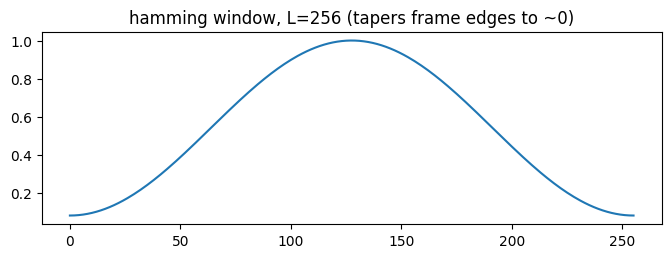

In [4]:
def pre_emphasis(x, alpha=PREEMPH):
    y = np.empty_like(x); y[0] = x[0]
    y[1:] = x[1:] - alpha * x[:-1]                      # y[n] = x[n] - alpha*x[n-1]
    return y

def n_frames_for(n_samples, L=FRAME_LEN, H=HOP):
    return (n_samples - L) // H + 1

def frame_signal(x, L=FRAME_LEN, H=HOP):
    assert x.ndim == 1 and len(x) >= L, "signal shorter than one frame"
    n = n_frames_for(len(x), L, H)
    idx = np.arange(L)[None, :] + H * np.arange(n)[:, None]    # (n, L): row k = k*H .. k*H+L-1
    return x[idx]

def window_frames(frames, kind=WINDOW):
    w = get_window(kind, frames.shape[1], fftbins=False)        # symmetric window, Eq. (1)
    return frames * w[None, :]

def preprocess(x):
    """raw (N,) -> pre-emphasised, framed, windowed (n_frames, 256)"""
    return window_frames(frame_signal(pre_emphasis(x)))

# ---- verification (works without the dataset) ----
y = pre_emphasis(np.array([1., 2., 3.]), 0.97); assert np.allclose(y, [1, 1.03, 1.06])
assert n_frames_for(1_000_000) == 7811
assert np.allclose(get_window("hamming", 5, fftbins=False), [0.08, 0.54, 1, 0.54, 0.08])
sig = np.random.randn(FS * 2).astype(np.float32)                # 2 s of noise
fw = preprocess(sig)
print("input", sig.shape, "-> frames", fw.shape, "| expected rows", n_frames_for(len(sig)))
assert fw.shape == (n_frames_for(len(sig)), FRAME_LEN)
w = get_window(WINDOW, FRAME_LEN, fftbins=False)
plt.figure(figsize=(8, 2.5)); plt.plot(w); plt.title(f"{WINDOW} window, L={FRAME_LEN} (tapers frame edges to ~0)"); plt.show()

---
# 3. Feature extraction and fusion
## 3a. The four features (each frame → one vector)



In [5]:
EPS = 1e-10

# ---------- MFCC ----------
def hz_to_mel(f): return 2595.0 * np.log10(1.0 + f / 700.0)
def mel_to_hz(m): return 700.0 * (10.0 ** (m / 2595.0) - 1.0)

def mel_filterbank(n_filt, n_fft, fs, fmin=0.0, fmax=None):
    """Triangular filters of Eq. (3) (standard falling edge). Returns (n_filt, n_fft//2+1)."""
    fmax = fmax or fs / 2
    centres_bins = mel_to_hz(np.linspace(hz_to_mel(fmin), hz_to_mel(fmax), n_filt + 2)) * n_fft / fs
    k = np.arange(n_fft // 2 + 1); H = np.zeros((n_filt, len(k)))
    for m in range(1, n_filt + 1):
        l, c, r = centres_bins[m - 1], centres_bins[m], centres_bins[m + 1]
        up, down = (k >= l) & (k <= c), (k > c) & (k <= r)
        H[m - 1, up]   = 2 * (k[up] - l) / ((r - l) * (c - l))
        H[m - 1, down] = 2 * (r - k[down]) / ((r - l) * (r - c))
    assert (H.sum(1) > 0).all(), "empty Mel filter: n_fft too small for this many filters"
    return H

def dct_matrix(M, n_coeff):
    m = np.arange(1, M + 1)[:, None]; n = np.arange(1, n_coeff + 1)[None, :]
    return np.cos(n * (m - 0.5) * np.pi / M)                  # Eq. (5), shape (M, n_coeff)

def mfcc_from_frames(frames_w, fs):
    spec = np.abs(np.fft.rfft(frames_w, n=FRAME_LEN, axis=1))          # Eq. (2) -> (n, 129)
    logE = np.log(spec @ mel_filterbank(N_MEL, FRAME_LEN, fs).T + EPS) # Eqs. (3),(4) -> (n, 20)
    return logE @ dct_matrix(N_MEL, N_MFCC)                            # Eq. (5) -> (n, 12)

# ---------- GFCC ----------
def erb(f): return 24.7 * (4.37 * f / 1000.0 + 1.0)                    # Eq. (8) with f = centre frequency
def gammatone_filterbank(n_filt, n_fft, fs, order=GAM_ORDER, fmin=50.0):
    erb_rate = lambda f: 21.4 * np.log10(1 + 0.00437 * f)
    inv_rate = lambda e: (10 ** (e / 21.4) - 1) / 0.00437
    fc = inv_rate(np.linspace(erb_rate(fmin), erb_rate(fs / 2), n_filt))   # equally spaced on ERB-rate scale
    b = 1.019 * erb(fc)                                                     # Eq. (7)
    f = np.arange(n_fft // 2 + 1) * fs / n_fft
    return (1 + ((f[None, :] - fc[:, None]) / b[:, None]) ** 2) ** (-order / 2)   # (n_filt, 129)

def gfcc_from_frames(frames_w, fs):
    spec = np.abs(np.fft.rfft(frames_w, n=FRAME_LEN, axis=1))
    E = spec @ gammatone_filterbank(N_GAM, FRAME_LEN, fs).T                # (n, 64)
    return np.cbrt(E) @ dct_matrix(N_GAM, N_GFCC)                          # cubic-root compression + DCT -> (n, 31)

# quick checks
assert abs(hz_to_mel(1000.0) - 1000.0) < 0.1 and abs(erb(1000.0) - 132.639) < 1e-3
assert np.allclose(dct_matrix(2, 1)[:, 0], [np.cos(np.pi / 4), np.cos(3 * np.pi / 4)])
Mt, Gt = mfcc_from_frames(fw, FS), gfcc_from_frames(fw, FS)
print("MFCC", Mt.shape, "GFCC", Gt.shape); assert Mt.shape[1] == 12 and Gt.shape[1] == 31 and np.isfinite(Mt).all() and np.isfinite(Gt).all()

MFCC (499, 12) GFCC (499, 31)


{'MFCC': (624, 12), 'GFCC': (624, 31), 'CQT': (624, 41), 'LOFAR': (624, 50)}
CQT peak bin: 28 | expected near 28 (100 Hz) or 16 (50 Hz)


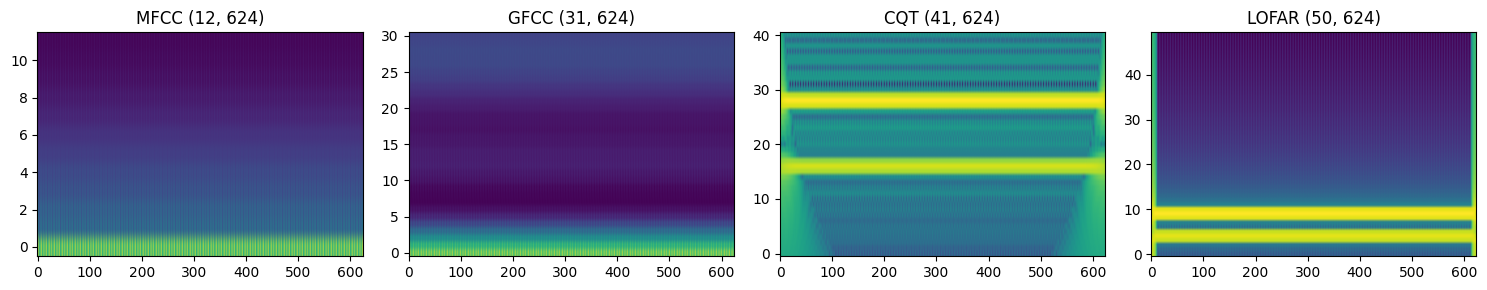

In [6]:
# ---------- CQT, Eq. (9) implemented directly ----------
def cqt_direct(x, fs, centres, fmin=CQT_FMIN, n_bins=CQT_BINS, bpo=CQT_BPO):
    """|X(m,n)| in dB at sample positions `centres`. Returns (len(centres), n_bins)."""
    Q = 1.0 / (2 ** (1.0 / bpo) - 1.0)
    out = np.empty((len(centres), n_bins), dtype=np.float32)
    for m in range(n_bins):
        fk = fmin * 2 ** (m / bpo)
        Nm = int(np.ceil(Q * fs / fk)); Nm += (Nm % 2 == 0)               # odd window length N_m
        k = np.arange(Nm)
        a = np.hamming(Nm) / Nm * np.exp(-2j * np.pi * Q * k / Nm)         # basis function a_m
        full = fftconvolve(x, np.conj(a)[::-1], mode="full")               # sliding sum of Eq. (9)
        out[:, m] = np.abs(full[centres + (Nm - 1) // 2])                  # value centred on sample n
    return 20 * np.log10(out + EPS)

# ---------- LOFAR (STFT, Eq. 10) ----------
def lofar_full(x, fs):
    n_fft = fs // LOFAR_STEP_HZ; assert fs % LOFAR_STEP_HZ == 0 and n_fft >= FRAME_LEN
    xp = np.pad(x, (n_fft // 2, n_fft // 2), mode="reflect")
    n = (len(xp) - n_fft) // HOP + 1
    idx = np.arange(n_fft)[None, :] + HOP * np.arange(n)[:, None]
    mag = np.abs(np.fft.rfft(xp[idx] * np.hanning(n_fft)[None, :], axis=1))   # frame j is centred on sample j*HOP
    return 20 * np.log10(mag[:, 1:LOFAR_BINS + 1] + EPS)                       # bins 1..50 = 10..500 Hz

# ---------- one clip -> aligned feature blocks ----------
def clip_features(x, fs):
    """x: mono clip (N,). Returns dict of (n_frames, d) blocks on a shared time axis."""
    n = n_frames_for(len(x))
    frames_w = preprocess(x)                                   # MFCC/GFCC path (frame k centre = k*HOP + FRAME_LEN/2 = (k+1)*HOP)
    centres = HOP * (np.arange(n) + 1)                         # same centres for CQT / LOFAR
    blocks = {"MFCC": mfcc_from_frames(frames_w, fs),
              "GFCC": gfcc_from_frames(frames_w, fs),
              "CQT":  cqt_direct(x.astype(np.float64), fs, centres),
              "LOFAR": lofar_full(x.astype(np.float64), fs)[1:1 + n]}   # row j has centre j*HOP -> rows 1..n
    for name, d in zip(blocks, (12, 31, 41, 50)):
        assert blocks[name].shape == (n, d), f"{name} shape {blocks[name].shape} != ({n},{d})"
    return blocks

# ---------- verification with known tones ----------
t = np.arange(int(2.5 * FS)) / FS
tone = np.sin(2 * np.pi * 100 * t) + 0.5 * np.sin(2 * np.pi * 50 * t)
B = clip_features(tone, FS)
print({k: v.shape for k, v in B.items()})
assert np.argmax(np.median(B["LOFAR"], axis=0)) == 9, "100 Hz must land in LOFAR column 9 (bin 10 -> 100 Hz)"
print("CQT peak bin:", np.argmax(np.median(B["CQT"], axis=0)),
      "| expected near", round(12 * np.log2(100 / CQT_FMIN)), "(100 Hz) or", round(12 * np.log2(50 / CQT_FMIN)), "(50 Hz)")
fig, ax = plt.subplots(1, 4, figsize=(15, 3))
for a, (k, v) in zip(ax, B.items()): a.imshow(v.T, origin="lower", aspect="auto"); a.set_title(f"{k} {v.shape[::-1]}")
plt.tight_layout(); plt.show()

## 3b. Fusion → MGCL (134), Delta, MGCL-Delta (268)



In [7]:
# ---------- fusion + delta ----------
def fuse_mgcl(blocks):                                           # Eq. (12), first fusion
    M = np.hstack([blocks["MFCC"], blocks["GFCC"], blocks["CQT"], blocks["LOFAR"]])
    assert M.shape[1] == 134, f"MGCL dim {M.shape[1]} != 134: check feature settings; do NOT pad"
    return M

def delta(C, N=DELTA_N):                                          # Eq. (11), along time (axis 0)
    T = len(C); P = np.pad(C, ((N, N), (0, 0)), mode="edge")
    num = sum(n * (P[N + n:N + n + T] - P[N - n:N - n + T]) for n in range(1, N + 1))
    return num / (2 * sum(n * n for n in range(1, N + 1)))

def fuse_mgcl_delta(blocks):                                      # second fusion
    M = fuse_mgcl(blocks); out = np.hstack([M, delta(M)])
    assert out.shape[1] == 268; return out.astype(np.float32)

# ---------- verification: hand example + independent reference (Savitzky-Golay slope = Eq. 11) ----------
c = np.array([[1.], [2.], [4.], [7.], [11.]]); assert abs(delta(c)[2, 0] - 2.5) < 1e-12
R = np.random.randn(50, 7)
assert np.allclose(delta(R), savgol_filter(R, 5, 1, deriv=1, axis=0, mode="nearest"))
print("delta matches hand calc and Savitzky-Golay reference")
F = fuse_mgcl_delta(B); print("MGCL-Delta for the test clip:", F.shape)

# ---------- dataset builder ----------
def load_clip(path, start, n):                                    # separated so it can be swapped in tests
    x, _ = sf.read(path, start=start, frames=n, dtype="float32", always_2d=True)
    return x[:, 0].astype(np.float64)                             # [CHOICE] channel 0 (mono expected)

def build_dataset(inv, fs, rng):
    clip_len = int(CLIP_SECONDS * fs); nf = n_frames_for(clip_len)
    per_clip = nf // FRAMES_PER_IMAGE; n_clips = math.ceil(IMAGES_PER_CLASS / per_clip)
    X, y, rec = [], [], []
    for label in CLASS_NAMES:
        pool = inv[(inv.label == label) & (inv.error == "") & (inv.n_samples >= clip_len)].reset_index(drop=True)
        assert len(pool) > 0, f"no usable recordings for {label}"
        imgs, rids = [], []
        for pi in rng.choice(len(pool), size=n_clips, replace=True):
            r = pool.iloc[pi]; start = int(rng.integers(0, r.n_samples - clip_len + 1))
            f = fuse_mgcl_delta(clip_features(load_clip(r.path, start, clip_len), fs))   # (nf, 268)
            imgs.append(f[:per_clip * FRAMES_PER_IMAGE].reshape(per_clip, FRAMES_PER_IMAGE, 268)); rids += [r.recording_id] * per_clip
        imgs = np.concatenate(imgs)[:IMAGES_PER_CLASS]
        X.append(imgs); y += [CLASS_TO_ID[label]] * len(imgs); rec += rids[:len(imgs)]
        print(f"{label}: {len(imgs)} images from {len(set(rids))} recordings")
    return np.concatenate(X), np.array(y), np.array(rec)

CACHE = OUT / "dataset_mgcl_delta.npz"
if CACHE.exists():
    d = np.load(CACHE, allow_pickle=True); X_all, y_all, rec_all = d["X"], d["y"], d["rec"]; print("loaded cache", X_all.shape)
elif inv is not None:
    t0 = time.time(); X_all, y_all, rec_all = build_dataset(inv, FS, np.random.default_rng(SEED))
    np.savez_compressed(CACHE, X=X_all, y=y_all, rec=rec_all); print(f"built {X_all.shape} in {time.time()-t0:.0f}s")
else:
    X_all = None; print("No dataset available: Sections 4-6 need it. Everything above was tested on synthetic audio.")
if X_all is not None:
    assert X_all.shape == (4 * IMAGES_PER_CLASS, FRAMES_PER_IMAGE, 268) and np.isfinite(X_all).all()

delta matches hand calc and Savitzky-Golay reference
MGCL-Delta for the test clip: (624, 268)
Tug: 2360 images from 3 recordings
Cargo: 2360 images from 10 recordings
Tanker: 2360 images from 14 recordings
Passengership: 2360 images from 10 recordings
built (9440, 5, 268) in 47s


---
# 4. Feature selection: Neighborhood Component Analysis (NCA)



device: cuda
split=random: train 6372 | val 708 | test 2360  (paper: 7080 train / 2360 test overall)
NCA fitted in 35s on 2000 train frames
kept 83 of 268 features (paper: 96)
feature  before  kept (static)  kept (delta)
   MFCC      12              3             0
   GFCC      31             14             1
    CQT      41             30             1
  LOFAR      50             32             2 
(paper Table II static after NCA: 7, 17, 11, 12)


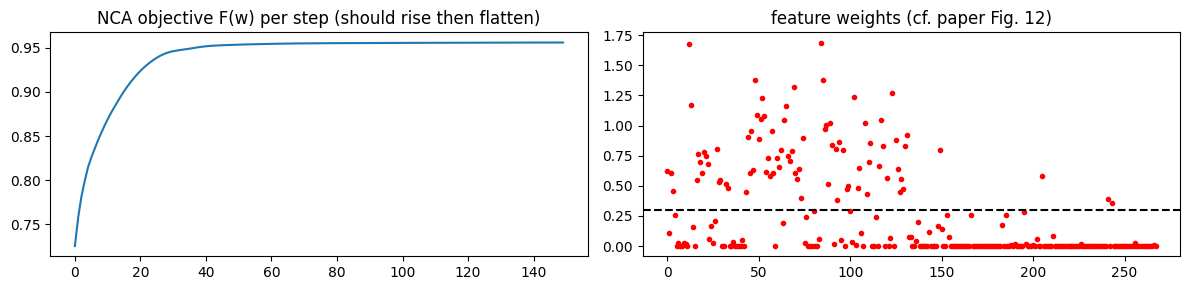

In [8]:
import torch
from sklearn.model_selection import train_test_split, GroupShuffleSplit
torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"; print("device:", DEVICE)

# ---------- split FIRST (before anything is fitted) ----------
def make_splits(y, rec, mode, seed=SEED):
    idx = np.arange(len(y))
    if mode == "random":                       # [PAPER] random 3/4 : 1/4 on image samples
        tr, te = train_test_split(idx, test_size=TEST_FRAC, stratify=y, random_state=seed)
        tr, va = train_test_split(tr, test_size=VAL_FRAC, stratify=y[tr], random_state=seed)
    elif mode == "recording":                  # [CHOICE] no recording appears on two sides; done per class so every class is in every split
        tr_l, va_l, te_l = [], [], []
        for c in np.unique(y):
            ic = idx[y == c]; assert len(np.unique(rec[ic])) >= 4, "recording-level split needs >= 4 recordings per class"
            g = GroupShuffleSplit(1, test_size=TEST_FRAC, random_state=seed); a, b = next(g.split(ic, groups=rec[ic])); trc, tec = ic[a], ic[b]
            g = GroupShuffleSplit(1, test_size=VAL_FRAC, random_state=seed); a, b = next(g.split(trc, groups=rec[trc]))
            tr_l.append(trc[a]); va_l.append(trc[b]); te_l.append(tec)
        tr, va, te = (np.concatenate(l) for l in (tr_l, va_l, te_l))
        assert not (set(rec[tr]) & set(rec[te])) and not (set(rec[va]) & set(rec[te])) and not (set(rec[tr]) & set(rec[va]))
    else: raise ValueError(mode)
    assert not (set(tr) & set(te)) and not (set(tr) & set(va)) and not (set(va) & set(te))
    return tr, va, te

if X_all is not None:
    tr, va, te = make_splits(y_all, rec_all, SPLIT_MODE)
    print(f"split={SPLIT_MODE}: train {len(tr)} | val {len(va)} | test {len(te)}  (paper: 7080 train / 2360 test overall)")
    assert len(np.unique(y_all[te])) == 4, "a class is missing from the test set"
    # ---------- standardise with TRAIN statistics only ----------
    frames_tr = X_all[tr].reshape(-1, 268)
    mu, sd = frames_tr.mean(0), frames_tr.std(0) + 1e-8
    Xs = ((X_all - mu) / sd).astype(np.float32)              # (N, 5, 268), same transform for val/test

# ---------- NCA (paper Eqs. 13-22) ----------
def fit_nca_weights(X, y, sigma=NCA_SIGMA, lam=NCA_LAMBDA, steps=NCA_STEPS, lr=NCA_LR):
    X = torch.tensor(X, dtype=torch.float32, device=DEVICE); y = torch.tensor(y, device=DEVICE)
    n, p = X.shape; lam = 1.0 / n if lam is None else lam
    w = torch.ones(p, device=DEVICE, requires_grad=True)
    same = (y[:, None] == y[None, :]).float(); eye = torch.eye(n, dtype=torch.bool, device=DEVICE)
    opt = torch.optim.Adam([w], lr=lr); hist = []
    for s in range(steps):
        Z = X * (w ** 2)                                      # |w^2 x_i - w^2 x_j|_1 = sum_r w_r^2 |x_ir - x_jr|  (Eq. 13)
        D = torch.cdist(Z, Z, p=1).masked_fill(eye, float("inf"))
        P = torch.softmax(-D / sigma, dim=1)                  # Eqs. (15)-(17), leave-one-out
        F = (P * same).sum(1).mean() - lam * (w ** 2).sum()   # Eqs. (18)-(22) (mean instead of sum, as in MATLAB fscnca)
        opt.zero_grad(); (-F).backward(); opt.step(); hist.append(F.item())
    return w.detach().abs().cpu().numpy(), hist

GROUPS = {"MFCC": (0, 12), "GFCC": (12, 43), "CQT": (43, 84), "LOFAR": (84, 134)}
if X_all is not None:
    rng = np.random.default_rng(SEED)
    fr = Xs[tr].reshape(-1, 268); ft = np.repeat(y_all[tr], FRAMES_PER_IMAGE)
    sub = rng.choice(len(fr), size=min(NCA_MAX_FRAMES, len(fr)), replace=False)       # TRAIN frames only
    t0 = time.time(); weights, hist = fit_nca_weights(fr[sub], ft[sub]); print(f"NCA fitted in {time.time()-t0:.0f}s on {len(sub)} train frames")
    sel = np.where(weights >= NCA_THRESHOLD)[0]                                      # [PAPER] threshold 0.3
    if TOP_K_FALLBACK: sel = np.sort(np.argsort(-weights)[:TOP_K_FALLBACK]); print(f"DEVIATION: top-{TOP_K_FALLBACK} instead of threshold")
    print(f"kept {len(sel)} of 268 features (paper: 96)")
    if len(sel) in (0, 268): print("WARNING: degenerate selection -> inspect the weight plot, adjust NCA_SIGMA / NCA_LAMBDA / NCA_STEPS")
    rows = [(g, b - a, int(((sel >= a) & (sel < b)).sum()), int(((sel >= a + 134) & (sel < b + 134)).sum())) for g, (a, b) in GROUPS.items()]
    print(pd.DataFrame(rows, columns=["feature", "before", "kept (static)", "kept (delta)"]).to_string(index=False), "\n(paper Table II static after NCA: 7, 17, 11, 12)")
    fig, ax = plt.subplots(1, 2, figsize=(12, 3))
    ax[0].plot(hist); ax[0].set_title("NCA objective F(w) per step (should rise then flatten)")
    ax[1].plot(weights, ".r"); ax[1].axhline(NCA_THRESHOLD, color="k", ls="--"); ax[1].set_title("feature weights (cf. paper Fig. 12)"); plt.tight_layout(); plt.show()

---
# 5. Classification: 2-D "images" + ResNet18


main-path conv layers: 17 | FC layers: 1 | maxpool: Identity
[('conv1', (2, 64, 3, 48)), ('layer1', (2, 64, 3, 48)), ('layer2', (2, 128, 2, 24)), ('layer3', (2, 256, 1, 12)), ('layer4', (2, 512, 1, 6))]
logits shape (2, 4) | params: 11178564
selected feature count K = 83
image tensor: (9440, 3, 5, 83)


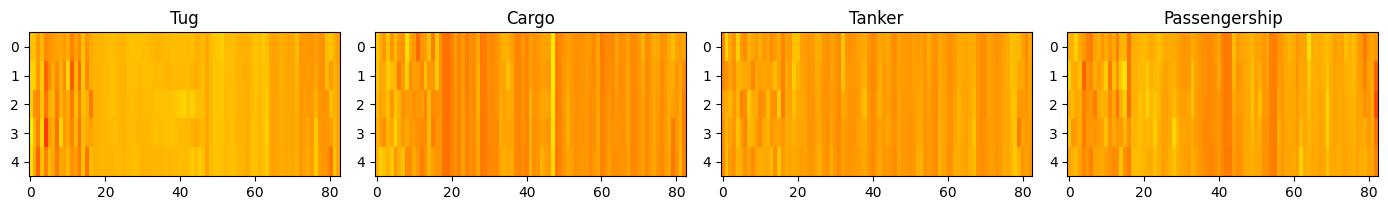

In [9]:
import torch.nn as nn, torchvision, matplotlib

def make_images(Xs, cols, train_idx, cmap="jet"):
    """(N,5,268) standardised -> (N,3,5,K) float tensor. Min/max from TRAIN only."""
    Z = Xs[:, :, cols]                                         # (N, 5, K)
    lo, hi = Z[train_idx].min(), Z[train_idx].max()
    Zn = np.clip((Z - lo) / (hi - lo + 1e-8), 0, 1)
    rgb = matplotlib.colormaps[cmap](Zn)[..., :3]              # (N, 5, K, 3)
    return torch.tensor(rgb.transpose(0, 3, 1, 2).copy(), dtype=torch.float32)

def build_resnet18(n_classes=4, in_hw=(5, 96), remove_global_pool=REMOVE_GLOBAL_POOL):
    m = torchvision.models.resnet18(weights=None, num_classes=n_classes)
    m.maxpool = nn.Identity()                                  # [PAPER] pooling layer removed ([CHOICE] which one)
    if remove_global_pool:
        feat = nn.Sequential(m.conv1, m.bn1, m.relu, m.layer1, m.layer2, m.layer3, m.layer4)
        with torch.no_grad(): c, h, w = feat(torch.zeros(1, 3, *in_hw)).shape[1:]
        m.avgpool = nn.Identity(); m.fc = nn.Linear(c * h * w, n_classes)
    return m

# ---------- architecture verification ----------
def check_arch(K=96):
    m = build_resnet18(in_hw=(5, K))
    n_conv_main = sum(isinstance(mod, nn.Conv2d) for name, mod in m.named_modules() if "downsample" not in name)
    n_fc = sum(isinstance(mod, nn.Linear) for mod in m.modules())
    print("main-path conv layers:", n_conv_main, "| FC layers:", n_fc, "| maxpool:", type(m.maxpool).__name__)
    assert n_conv_main == 17 and n_fc == 1                     # matches the paper's "17 conv + 1 FC"
    x = torch.zeros(2, 3, 5, K); shapes = []
    with torch.no_grad():
        x = m.relu(m.bn1(m.conv1(x))); shapes.append(("conv1", tuple(x.shape)))
        for n in ("layer1", "layer2", "layer3", "layer4"): x = getattr(m, n)(x); shapes.append((n, tuple(x.shape)))
        out = m(torch.zeros(2, 3, 5, K))
    print(shapes); assert out.shape == (2, 4); print("logits shape", tuple(out.shape), "| params:", sum(p.numel() for p in m.parameters()))
check_arch(96)

if X_all is not None:
    K = len(sel); print("selected feature count K =", K)
    X_img = make_images(Xs, sel, tr)                           # (N, 3, 5, K)
    y_t = torch.tensor(y_all, dtype=torch.long); print("image tensor:", tuple(X_img.shape))
    fig, ax = plt.subplots(1, 4, figsize=(14, 2.2))
    for c in range(4):
        i = np.where(y_all[te] == c)[0][0]; ax[c].imshow(X_img[te][i].permute(1, 2, 0).numpy(), aspect="auto"); ax[c].set_title(CLASS_NAMES[c])
    plt.tight_layout(); plt.show()

---
# 6. Evaluation: train, test, compare with the paper



[MGCL-Delta-NCA] epoch 1/15  train_loss 0.8021  val_loss 0.6570  val_acc 0.7133
[MGCL-Delta-NCA] epoch 2/15  train_loss 0.3382  val_loss 0.2142  val_acc 0.9082
[MGCL-Delta-NCA] epoch 3/15  train_loss 0.1723  val_loss 0.0820  val_acc 0.9774
[MGCL-Delta-NCA] epoch 4/15  train_loss 0.1119  val_loss 0.0727  val_acc 0.9661
[MGCL-Delta-NCA] epoch 5/15  train_loss 0.0705  val_loss 0.0315  val_acc 0.9929
[MGCL-Delta-NCA] epoch 6/15  train_loss 0.0411  val_loss 0.0302  val_acc 0.9929
[MGCL-Delta-NCA] epoch 7/15  train_loss 0.0295  val_loss 0.0394  val_acc 0.9859
[MGCL-Delta-NCA] epoch 8/15  train_loss 0.0229  val_loss 0.0386  val_acc 0.9873
[MGCL-Delta-NCA] epoch 9/15  train_loss 0.0142  val_loss 0.0120  val_acc 0.9972
[MGCL-Delta-NCA] epoch 10/15  train_loss 0.0164  val_loss 0.0212  val_acc 0.9929
[MGCL-Delta-NCA] epoch 11/15  train_loss 0.0121  val_loss 0.0169  val_acc 0.9929
[MGCL-Delta-NCA] epoch 12/15  train_loss 0.0062  val_loss 0.0241  val_acc 0.9915
[MGCL-Delta-NCA] epoch 13/15  train_l

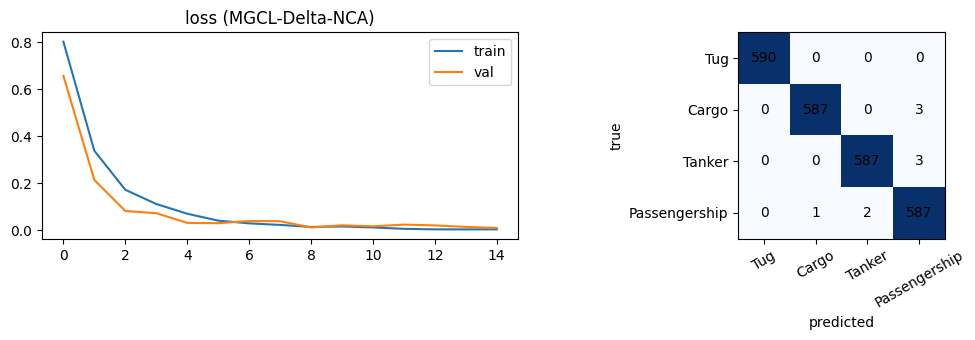

In [10]:
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, precision_recall_fscore_support

def predict(model, X, bs=256):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), bs): out.append(model(X[i:i + bs].to(DEVICE)).argmax(1).cpu())
    return torch.cat(out).numpy()

def train_model(X, y, tr_idx, va_idx, K, name, epochs=EPOCHS):
    torch.manual_seed(SEED)
    model = build_resnet18(in_hw=(FRAMES_PER_IMAGE, K)).to(DEVICE)
    opt = torch.optim.SGD(model.parameters(), lr=LR, momentum=MOMENTUM)          # SGDM [PAPER]
    loss_fn = nn.CrossEntropyLoss()
    g = torch.Generator().manual_seed(SEED)
    loader = DataLoader(TensorDataset(X[tr_idx], y[tr_idx]), batch_size=BATCH, shuffle=True, generator=g)   # [PAPER] batch 5
    hist = {"train_loss": [], "val_loss": [], "val_acc": []}; best = -1; ckpt = OUT / f"{name}_best.pt"
    for ep in range(epochs):
        model.train(); tl = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad(); loss = loss_fn(model(xb), yb); loss.backward(); opt.step(); tl += loss.item() * len(xb)
        model.eval()
        with torch.no_grad():
            xv, yv = X[va_idx].to(DEVICE), y[va_idx].to(DEVICE)
            vl = sum(loss_fn(model(xv[i:i+256]), yv[i:i+256]).item() * len(yv[i:i+256]) for i in range(0, len(xv), 256)) / len(xv)
        va = accuracy_score(y[va_idx].numpy(), predict(model, X[va_idx]))
        hist["train_loss"].append(tl / len(tr_idx)); hist["val_loss"].append(vl); hist["val_acc"].append(va)
        if va > best: best = va; torch.save(model.state_dict(), ckpt)               # checkpoint = best validation accuracy
        print(f"[{name}] epoch {ep+1}/{epochs}  train_loss {hist['train_loss'][-1]:.4f}  val_loss {vl:.4f}  val_acc {va:.4f}")
    model.load_state_dict(torch.load(ckpt)); return model, hist

def evaluate(model, X, y, title):
    pred = predict(model, X[te]); true = y[te].numpy()
    acc = accuracy_score(true, pred); cm = confusion_matrix(true, pred, labels=range(4))
    p, r, f, _ = precision_recall_fscore_support(true, pred, average="macro", zero_division=0)
    print(f"\n{title}: TEST accuracy {acc*100:.2f}% | macro precision {p*100:.2f} | recall {r*100:.2f} | F1 {f*100:.2f}")
    print(classification_report(true, pred, target_names=CLASS_NAMES, digits=4, zero_division=0))
    return dict(acc=acc, precision=p, recall=r, f1=f, cm=cm)

def plot_results(hist, cm, title):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(hist["train_loss"], label="train"); ax[0].plot(hist["val_loss"], label="val"); ax[0].legend(); ax[0].set_title(f"loss ({title})")
    im = ax[1].imshow(cm, cmap="Blues"); ax[1].set_xticks(range(4), CLASS_NAMES, rotation=30); ax[1].set_yticks(range(4), CLASS_NAMES)
    for i in range(4):
        for j in range(4): ax[1].text(j, i, cm[i, j], ha="center", va="center")
    ax[1].set_xlabel("predicted"); ax[1].set_ylabel("true"); plt.tight_layout(); plt.show()

RESULTS = {}
if X_all is not None:
    model, hist = train_model(X_img, y_t, tr, va, K=len(sel), name="MGCL-Delta-NCA")
    RESULTS["MGCL-Delta-NCA"] = evaluate(model, X_img, y_t, "MGCL-Delta-NCA + ResNet18")
    plot_results(hist, RESULTS["MGCL-Delta-NCA"]["cm"], "MGCL-Delta-NCA")

In [12]:
# ---------- comparison with the paper (paper numbers are THEIR measurements, not ours) ----------
PAPER = {"MFCC": 90.16, "MGCL": 92.59, "MGCL-Delta": 95.35, "MGCL-Delta-NCA": 97.29}    # Table III, 2-D, ResNet18

RUN_ABLATION = False     # True: also train MFCC / MGCL / MGCL-Delta (3 more trainings; slow)
if X_all is not None and RUN_ABLATION:
    for name, cols in {"MFCC": np.arange(0, 12), "MGCL": np.arange(0, 134), "MGCL-Delta": np.arange(0, 268)}.items():
        Xi = make_images(Xs, cols, tr)
        m_, h_ = train_model(Xi, y_t, tr, va, K=len(cols), name=name); RESULTS[name] = evaluate(m_, Xi, y_t, name)

if RESULTS:
    tab = pd.DataFrame([{"features": k, "paper acc %": PAPER[k], "OUR measured acc %": round(v["acc"] * 100, 2),
                         "split": SPLIT_MODE, "epochs": EPOCHS} for k, v in RESULTS.items()])
    print(tab.to_string(index=False)); tab.to_csv(OUT / f"comparison_{SPLIT_MODE}.csv", index=False)
    print("\nReading it honestly: differences vs the paper can come from the split (random vs recording-level), our CHOICES above"
          "\n(window, pre-emphasis, CQT/LOFAR settings, NCA sigma/lambda, momentum, epochs), clip sampling, seeds, hardware.")
    print("Re-run with SPLIT_MODE='recording' (and delete outputs/dataset cache only if you change feature settings) to measure leakage.")
else:
    print("No results yet: run Sections 1-6 on the real dataset.")

      features  paper acc %  OUR measured acc %  split  epochs
MGCL-Delta-NCA        97.29               99.62 random      15

Reading it honestly: differences vs the paper can come from the split (random vs recording-level), our CHOICES above
(window, pre-emphasis, CQT/LOFAR settings, NCA sigma/lambda, momentum, epochs), clip sampling, seeds, hardware.
Re-run with SPLIT_MODE='recording' (and delete outputs/dataset cache only if you change feature settings) to measure leakage.
